In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
#импорт необходимых библиотек

In [4]:
data_path = "data\Social_media_impact_on_life.csv" # исп. относительного пути для импорта
df = pd.read_csv(data_path)

In [6]:
df.head() # можно использовать df.tail()

,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial


In [8]:
df.shape

(4500, 16)

In [9]:
df.columns

Index(['Student_ID', 'Age', 'Gender', 'Academic_Level', 'Primary_Platform',
       'Daily_Usage_Hours', 'Weekend_Extra_Hours', 'Device_Type',
       'Sleep_Duration_Hours', 'Sleep_Quality_Score', 'Late_Night_Usage',
       'Social_Comparison_Frequency', 'Perceived_Stress_Score',
       'Mental_Health_Index', 'Academic_Performance_GPA', 'Overall_Impact'],
      dtype='str')

In [10]:
df.dtypes

Student_ID                         str
Age                              int64
Gender                             str
Academic_Level                     str
Primary_Platform                   str
Daily_Usage_Hours              float64
Weekend_Extra_Hours            float64
Device_Type                        str
Sleep_Duration_Hours           float64
Sleep_Quality_Score              int64
Late_Night_Usage                  bool
Social_Comparison_Frequency        str
Perceived_Stress_Score         float64
Mental_Health_Index              int64
Academic_Performance_GPA       float64
Overall_Impact                     str
dtype: object

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Student_ID                   4500 non-null   str    
 1   Age                          4500 non-null   int64  
 2   Gender                       4500 non-null   str    
 3   Academic_Level               4500 non-null   str    
 4   Primary_Platform             4500 non-null   str    
 5   Daily_Usage_Hours            4500 non-null   float64
 6   Weekend_Extra_Hours          4500 non-null   float64
 7   Device_Type                  4500 non-null   str    
 8   Sleep_Duration_Hours         4500 non-null   float64
 9   Sleep_Quality_Score          4500 non-null   int64  
 10  Late_Night_Usage             4500 non-null   bool   
 11  Social_Comparison_Frequency  4500 non-null   str    
 12  Perceived_Stress_Score       4454 non-null   float64
 13  Mental_Health_Index          

In [12]:
df[df['Academic_Performance_GPA'].isna()]['Academic_Level'].value_counts() 

Academic_Level
Undergraduate    56
High School      27
Postgraduate      2
Name: count, dtype: int64

In [22]:
df['Academic_Performance_GPA'].isna().groupby(df['Academic_Level']).mean() * 100 

Academic_Level
High School      1.828030
Postgraduate     0.813008
Undergraduate    2.016565
Name: Academic_Performance_GPA, dtype: float64

Посмотрели, в каких группах и в каком процентном соотношении есть пропуски. Проценты пропусков в каждой группе незначительные, скорее всего, пропуски случайные.

<Axes: xlabel='Daily_Usage_Hours', ylabel='Count'>

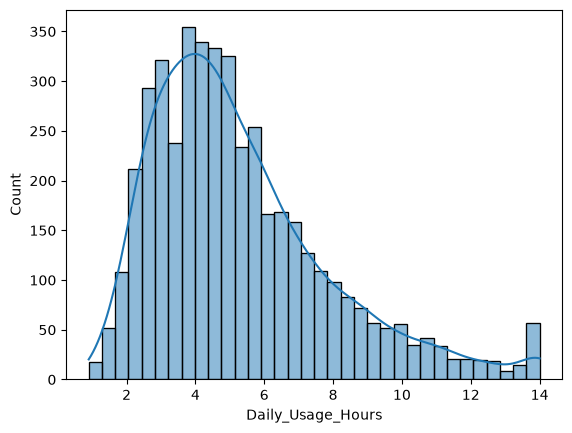

In [24]:
sns.histplot(df['Daily_Usage_Hours'], kde = True)

In [37]:
df['Daily_Usage_Hours'].agg(['mean', 'median'])

mean      5.295933
median    4.700000
Name: Daily_Usage_Hours, dtype: float64

Среднее немного больше медианы, т.к справа есть 'Хвост'.

<Axes: xlabel='Sleep_Duration_Hours', ylabel='Count'>

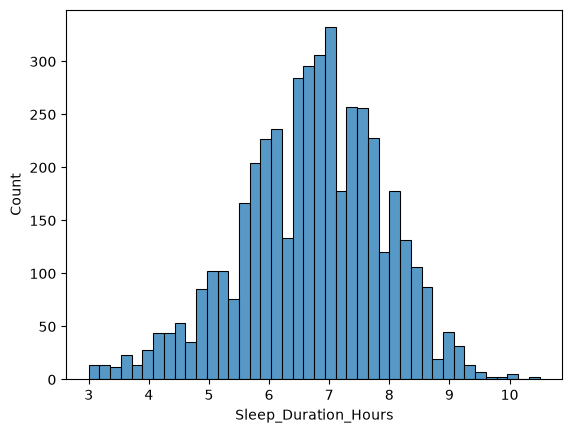

In [30]:
sns.histplot(df['Sleep_Duration_Hours'])

In [41]:
df['Sleep_Duration_Hours'].agg(['mean','median']) 

mean      6.701333
median    6.800000
Name: Sleep_Duration_Hours, dtype: float64

Распределение симметричное, т.к нет "Хвостов".

<Axes: xlabel='Mental_Health_Index', ylabel='Count'>

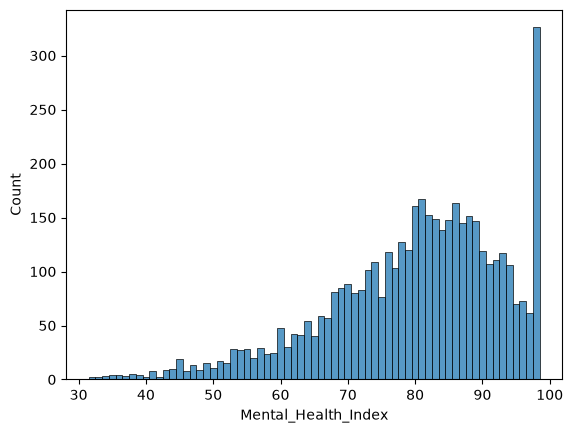

In [40]:
sns.histplot(df['Mental_Health_Index'], discrete = True)

In [39]:
df['Mental_Health_Index'].agg(['mean','median'])

mean      79.873111
median    82.000000
Name: Mental_Health_Index, dtype: float64

**Вывод**

Видим, что среднее немного ниже медианы. У небольшой группы студентов индекс психического здоровья заметно ниже, чем у большинства и они тянут среднее вниз.

<Axes: xlabel='Primary_Platform', ylabel='count'>

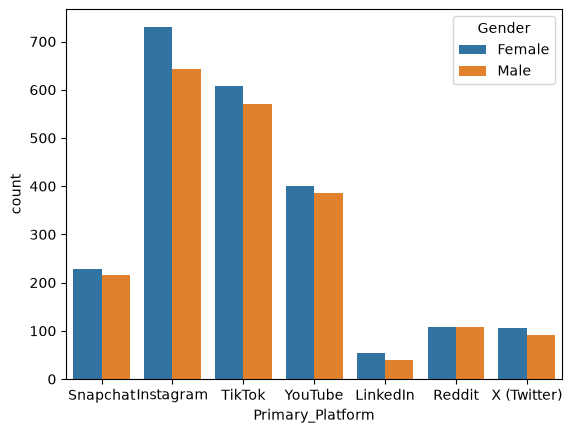

In [36]:
sns.countplot(x=df['Primary_Platform'], hue =df['Gender'], hue_order=['Female','Male']) # исключены малые группы для наглядности